# ----- Voting Ensembling Technique ----- 

In [62]:
import warnings 
warnings.filterwarnings('ignore')

In [2]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from tqdm import tqdm
from sklearn.compose import make_column_transformer, make_column_selector
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

from sklearn.ensemble import VotingClassifier

In [3]:
df = pd.read_csv(r"C:\Users\PGCP-AI.STUDENTSDC\Desktop\Machine_Learning\Cases\Wisconsin\BreastCancer.csv",index_col=0)
df.sample(5)

,Clump,UniCell_Size,Uni_CellShape,MargAdh,SEpith,BareN,BChromatin,NoemN,Mitoses,Class
Code,,,,,,,,,,
508234,7,4,5,10,2,10,3,8,2,Malignant
1096352,6,3,3,3,3,2,6,1,1,Benign
557583,5,10,10,10,10,10,10,1,1,Malignant
1157734,4,1,1,1,2,1,3,1,1,Benign
1091262,2,5,3,3,6,7,7,5,1,Malignant


In [4]:
X , y = df.drop('Class',axis=1) , df['Class']
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.3,random_state=26,stratify=y)

In [5]:
tree = DecisionTreeClassifier(random_state=26)
lr = LogisticRegression()
knn = KNeighborsClassifier()

voting = VotingClassifier([('TREE',tree),('LR',lr),('KNN',knn)])
voting.fit(X_train,y_train)

,"estimators estimators: list of (str, estimator) tuplesInvoking the ``fit`` method on the ``VotingClassifier`` will fit clonesof those original estimators that will be stored in the class attribute``self.estimators_``. An estimator can be set to ``'drop'`` using:meth:`set_params`... versionchanged:: 0.21 ``'drop'`` is accepted. Using None was deprecated in 0.22 and support was removed in 0.24.","[('TREE', ...), ('LR', ...), ...]"
,"voting voting: {'hard', 'soft'}, default='hard'If 'hard', uses predicted class labels for majority rule voting.Else if 'soft', predicts the class label based on the argmax ofthe sums of the predicted probabilities, which is recommended foran ensemble of well-calibrated classifiers.",'hard'
,"weights weights: array-like of shape (n_classifiers,), default=NoneSequence of weights (`float` or `int`) to weight the occurrences ofpredicted class labels (`hard` voting) or class probabilitiesbefore averaging (`soft` voting). Uses uniform weights if `None`.",None
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for ``fit``.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionadded:: 0.18",None
,"flatten_transform flatten_transform: bool, default=TrueAffects shape of transform output only when voting='soft'If voting='soft' and flatten_transform=True, transform method returnsmatrix with shape (n_samples, n_classifiers * n_classes). Ifflatten_transform=False, it returns(n_classifiers, n_samples, n_classes).",True
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting will be printed as itis completed... versionadded:: 0.23",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels.","ndarray[object](2,)","['Benign','Malignant']"
"estimators_ estimators_: list of classifiersThe collection of fitted sub-estimators as defined in ``estimators``that are not 'drop'. Note that sub-estimators are always fitted oninteger-encoded labels (see ``le_`` attribute). When ``y`` containsnon-integer class labels (e.g. strings), use ``le_.inverse_transform``to map predictions back to the original label space.",list,"[DecisionTreeC...ndom_state=26), LogisticRegression(), KNeighborsClassifier()]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimators expose such an attribute when fit... versionadded:: 1.0","ndarray[object](9,)","['Clump','UniCell_Size','Uni_CellShape',...,'BChromatin','NoemN','Mitoses']"
le_ le_: :class:`~sklearn.preprocessing.LabelEncoder`Transformer used to encode the labels during fit and decode duringprediction. Sub-estimators in ``estimators_`` are fitted on theinteger-encoded labels produced by this encoder.,LabelEncoder,LabelEncoder()


In [6]:
y_pred = voting.predict(X_test)
accuracy_score(y_test,y_pred)

0.9571428571428572

In [7]:
voting.named_estimators_

{'TREE': DecisionTreeClassifier(random_state=26),
 'LR': LogisticRegression(),
 'KNN': KNeighborsClassifier()}

In [8]:
voting.named_estimators_['TREE']

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",26
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples

### Performnace Of Individual Estimators

In [9]:
import numpy as np
y_test_enc = np.where(y_test == "Malignant",1,0)
y_pred = voting.named_estimators_['TREE'].predict(X_test)
print('Tree Accuracy ->',accuracy_score(y_test_enc,y_pred))
y_pred = voting.named_estimators_['LR'].predict(X_test)
print('LR Accuracy ->',accuracy_score(y_test_enc,y_pred))
y_pred = voting.named_estimators_['KNN'].predict(X_test)
print('KNN Accuracy ->',accuracy_score(y_test_enc,y_pred))

Tree Accuracy -> 0.9476190476190476
LR Accuracy -> 0.9619047619047619
KNN Accuracy -> 0.9619047619047619


In [10]:
scores = []
for d in tqdm([None,2,3,4,5]):
    for s in ['lbfgs','saga','sag','liblinear']:
        for k in [2,5,10]:           
            tree = DecisionTreeClassifier(random_state=26,max_depth=d)
            lr = LogisticRegression(solver=s)
            knn = KNeighborsClassifier(n_neighbors=k)
            voting = VotingClassifier([('TREE',tree),('LR',lr),('KNN',knn)],voting='soft')  
            # voting = soft -> Predicted class probabilities , and avg them
            # default : Voting = hard -> predict class label , and majority is choosen
            voting.fit(X_train,y_train)
            y_pred = voting.predict(X_test)
            scores.append([d,s,k,accuracy_score(y_test,y_pred)])

100%|██████████| 5/5 [00:01<00:00,  3.08it/s]


In [11]:
df_scores = pd.DataFrame(scores,columns=['Depth','Solver','Neighbors','Accuracy'])
df_scores.sort_values('Accuracy',ascending=False)

,Depth,Solver,Neighbors,Accuracy
27,3.0,saga,2,0.971429
24,3.0,lbfgs,2,0.971429
33,3.0,liblinear,2,0.971429
30,3.0,sag,2,0.971429
36,4.0,lbfgs,2,0.971429
39,4.0,saga,2,0.971429
45,4.0,liblinear,2,0.971429
42,4.0,sag,2,0.971429
21,2.0,liblinear,2,0.966667
18,2.0,sag,2,0.966667


# Exercise

In [12]:
df = pd.read_csv(r"C:\Users\PGCP-AI.STUDENTSDC\Desktop\Machine_Learning\Cases\Concrete_Strength\Concrete_Data.csv")
df.sample(5)

,Cement,Blast,Fly,Water,Superplasticizer,Coarse,Fine,Age,Strength
691,212.0,141.3,0.0,203.5,0.0,973.4,750.0,3,6.81
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30
604,339.0,0.0,0.0,197.0,0.0,968.0,781.0,365,38.89
363,218.2,54.6,123.8,140.8,11.9,1075.7,792.7,100,63.53
865,265.0,111.0,86.0,195.0,6.0,833.0,790.0,28,41.54


In [13]:
X , y = df.drop('Strength',axis=1) , df['Strength']
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.3,random_state=26)

In [14]:
from sklearn.linear_model import LinearRegression,Ridge,Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import VotingRegressor
from sklearn.metrics import r2_score

In [15]:
lr = LinearRegression()
rd = Ridge()
ls = Lasso()
dtr = DecisionTreeRegressor(random_state=26)

In [16]:
voting = VotingRegressor([('LR',lr),('RD',rd),('LS',ls),('TREE',dtr)])
voting.fit(X_train,y_train)

,"estimators estimators: list of (str, estimator) tuplesInvoking the ``fit`` method on the ``VotingRegressor`` will fit clonesof those original estimators that will be stored in the class attribute``self.estimators_``. An estimator can be set to ``'drop'`` using:meth:`set_params`... versionchanged:: 0.21 ``'drop'`` is accepted. Using None was deprecated in 0.22 and support was removed in 0.24.","[('LR', ...), ('RD', ...), ...]"
,"weights weights: array-like of shape (n_regressors,), default=NoneSequence of weights (`float` or `int`) to weight the occurrences ofpredicted values before averaging. Uses uniform weights if `None`.",None
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for ``fit``.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting will be printed as itis completed... versionadded:: 0.23",False
Name,Type,Value
estimators_ estimators_: list of regressorsThe collection of fitted sub-estimators as defined in ``estimators``that are not 'drop'.,list,"[LinearRegression(), Ridge(), Lasso(), DecisionTreeR...ndom_state=26)]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimators expose such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['Cement','Blast','Fly',...,'Coarse','Fine','Age']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying regressor exposes such an attribute when fit... versionadded:: 0.24,int,8
named_estimators_ named_estimators_: :class:`~sklearn.utils.Bunch`Attribute to access any fitted sub-estimators by name... versionadded:: 0.20,Bunch,{'LR': Linear...dom_state=26)}
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True


In [17]:
y_pred = voting.predict(X_test)
r2_score(y_test,y_pred)

0.7557599363240081

In [18]:
# Estimate Individual Estimator
y_pred = voting.named_estimators_['LR'].predict(X_test)
print('R2 Score For Linear ->',r2_score(y_test,y_pred))
y_pred = voting.named_estimators_['RD'].predict(X_test)
print('R2 Score For Ridge ->',r2_score(y_test,y_pred))
y_pred = voting.named_estimators_['LS'].predict(X_test)
print('R2 Score For Lasso ->',r2_score(y_test,y_pred))
y_pred = voting.named_estimators_['TREE'].predict(X_test)
print('R2 Score For Tree ->',r2_score(y_test,y_pred))

R2 Score For Linear -> 0.6181464728464399
R2 Score For Ridge -> 0.6181470326108837
R2 Score For Lasso -> 0.6188405404462809
R2 Score For Tree -> 0.8500256114787615


### Apply Weights

In [19]:
voting = VotingRegressor([('LR',lr),('RD',rd),('LS',ls),('TREE',dtr)],
                        weights=[0.9,0.9,1,10])
voting.fit(X_train,y_train)

,"estimators estimators: list of (str, estimator) tuplesInvoking the ``fit`` method on the ``VotingRegressor`` will fit clonesof those original estimators that will be stored in the class attribute``self.estimators_``. An estimator can be set to ``'drop'`` using:meth:`set_params`... versionchanged:: 0.21 ``'drop'`` is accepted. Using None was deprecated in 0.22 and support was removed in 0.24.","[('LR', ...), ('RD', ...), ...]"
,"weights weights: array-like of shape (n_regressors,), default=NoneSequence of weights (`float` or `int`) to weight the occurrences ofpredicted values before averaging. Uses uniform weights if `None`.","[0.9, 0.9, ...]"
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for ``fit``.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting will be printed as itis completed... versionadded:: 0.23",False
Name,Type,Value
estimators_ estimators_: list of regressorsThe collection of fitted sub-estimators as defined in ``estimators``that are not 'drop'.,list,"[LinearRegression(), Ridge(), Lasso(), DecisionTreeR...ndom_state=26)]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimators expose such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['Cement','Blast','Fly',...,'Coarse','Fine','Age']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying regressor exposes such an attribute when fit... versionadded:: 0.24,int,8
named_estimators_ named_estimators_: :class:`~sklearn.utils.Bunch`Attribute to access any fitted sub-estimators by name... versionadded:: 0.20,Bunch,{'LR': Linear...dom_state=26)}
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True


In [20]:
y_pred = voting.predict(X_test)
r2_score(y_test,y_pred)

0.8717692447087042

# ----- Bootstrap Sampling Estimation Technique -----

Ex :- RandomForest()

In [21]:
from sklearn.ensemble import BaggingClassifier

In [22]:
df = pd.read_csv(r"C:\Users\PGCP-AI.STUDENTSDC\Desktop\Machine_Learning\Cases\Wisconsin\BreastCancer.csv",index_col=0)
df.sample(5)

,Clump,UniCell_Size,Uni_CellShape,MargAdh,SEpith,BareN,BChromatin,NoemN,Mitoses,Class
Code,,,,,,,,,,
1212422,3,1,1,1,2,1,3,1,1,Benign
428598,1,1,3,1,1,1,2,1,1,Benign
836433,5,1,1,3,2,1,1,1,1,Benign
672113,7,5,6,10,4,10,5,3,1,Malignant
1198641,10,10,6,3,3,10,4,3,2,Malignant


In [23]:
X , y = df.drop('Class',axis=1) , df['Class']
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.3,random_state=26,stratify=y)

In [24]:
lr = LogisticRegression()
bagg = BaggingClassifier(estimator=lr,n_estimators=15,random_state=26)
bagg.fit(X_train,y_train)

,"estimator estimator: object, default=NoneThe base estimator to fit on random subsets of the dataset.If None, then the base estimator is a:class:`~sklearn.tree.DecisionTreeClassifier`... versionadded:: 1.2 `base_estimator` was renamed to `estimator`.",LogisticRegression()
,"n_estimators n_estimators: int, default=10The number of base estimators in the ensemble.",15
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random resampling of the original dataset(sample wise and feature wise).If the base estimator accepts a `random_state` attribute, a differentseed is generated for each instance in the ensemble.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",26
,"max_samples max_samples: int or float, default=NoneThe number of samples to draw from X to train each base estimator (withreplacement by default, see `bootstrap` for more details).- If None, then draw `X.shape[0]` samples irrespective of `sample_weight`.- If int, then draw `max_samples` samples.- If float, then draw `max_samples * X.shape[0]` unweighted samples or `max_samples * sample_weight.sum()` weighted samples.",None
,"max_features max_features: int or float, default=1.0The number of features to draw from X to train each base estimator (without replacement by default, see `bootstrap_features` for moredetails).- If int, then draw `max_features` features.- If float, then draw `max(1, int(max_features * n_features_in_))` features.",1.0
,"bootstrap bootstrap: bool, default=TrueWhether samples are drawn with replacement. If False, sampling withoutreplacement is performed. If fitting with `sample_weight`, it isstrongly recommended to choose True, as only drawing with replacementwill ensure the expected frequency semantics of `sample_weight`.",True
,"bootstrap_features bootstrap_features: bool, default=FalseWhether features are drawn with replacement.",False
,"oob_score oob_score: bool, default=FalseWhether to use out-of-bag samples to estimatethe generalization error. Only available if bootstrap=True.",False
,"warm_start warm_start: bool, default=FalseWhen set to True, reuse the solution of the previous call to fitand add more estimators to the ensemble, otherwise, just fita whole new ensemble. See :term:`the Glossary <warm_start>`... versionadded:: 0.17 *warm_start* constructor parameter.",False
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for both :meth:`fit` and:meth:`predict`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"verbose verbose: int, default=0Controls the verbosity when fitting and predicting.",0


In [25]:
y_pred = bagg.predict(X_test)
accuracy_score(y_pred,y_test)

0.9571428571428572

In [26]:
lr = LogisticRegression()
knn = KNeighborsClassifier()
dtc = DecisionTreeClassifier(random_state=26)

In [27]:
est = [lr,knn,dtc]
n_samples = [10,25,50]
scores = []
for e in est :
    for n in n_samples:
        bagg = BaggingClassifier(estimator=e,n_estimators=n,random_state=26)
        bagg.fit(X_train,y_train)
        y_pred = bagg.predict(X_test)
        scores.append([e,n,accuracy_score(y_test,y_pred)])
df_scores = pd.DataFrame(scores, columns=['Estimator','N','Accuracy'])
df_scores.sort_values('Accuracy',ascending=False)

,Estimator,N,Accuracy
6,DecisionTreeClassifier(random_state=26),10,0.966667
5,KNeighborsClassifier(),50,0.966667
7,DecisionTreeClassifier(random_state=26),25,0.966667
3,KNeighborsClassifier(),10,0.961905
2,LogisticRegression(),50,0.961905
8,DecisionTreeClassifier(random_state=26),50,0.961905
4,KNeighborsClassifier(),25,0.961905
1,LogisticRegression(),25,0.957143
0,LogisticRegression(),10,0.952381


# Exercise on concrete.csv -> algo LR,RD,LS,TREE
Regression

In [28]:
df = pd.read_csv(r"C:\Users\PGCP-AI.STUDENTSDC\Desktop\Machine_Learning\Cases\Concrete_Strength\Concrete_Data.csv")
df.sample(5)

,Cement,Blast,Fly,Water,Superplasticizer,Coarse,Fine,Age,Strength
85,379.5,151.2,0.0,153.9,15.9,1134.3,605.0,3,28.60
401,475.0,0.0,0.0,162.0,9.5,1044.0,662.0,28,58.52
991,309.9,142.8,111.2,167.8,22.1,913.9,651.2,28,38.22
74,375.0,93.8,0.0,126.6,23.4,852.1,992.6,3,29.00
389,500.1,0.0,0.0,200.0,3.0,1124.4,613.2,28,44.13


In [29]:
X , y = df.drop('Strength',axis=1) , df['Strength']
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.3,random_state=26)

In [30]:
from sklearn.ensemble import BaggingRegressor

In [31]:
lr = LinearRegression()
est = [lr,rd,ls,dtr]
n_samples = [10,25,50]
scores = []
for e in tqdm(est) :
    for n in n_samples:
        bagg = BaggingRegressor(estimator=e,n_estimators=n,random_state=26)
        bagg.fit(X_train,y_train)
        y_pred = bagg.predict(X_test)
        scores.append([e,n,r2_score(y_test,y_pred)])
df_scores = pd.DataFrame(scores, columns=['Estimator','N','R2 Score'])
df_scores.sort_values('R2 Score',ascending=False)

100%|██████████| 4/4 [00:01<00:00,  3.15it/s]


,Estimator,N,R2 Score
11,DecisionTreeRegressor(random_state=26),50,0.896730
10,DecisionTreeRegressor(random_state=26),25,0.893895
9,DecisionTreeRegressor(random_state=26),10,0.893069
6,Lasso(),10,0.620327
3,Ridge(),10,0.619630
0,LinearRegression(),10,0.619629
8,Lasso(),50,0.618218
5,Ridge(),50,0.617487
2,LinearRegression(),50,0.617486
7,Lasso(),25,0.616078


# ----- Boosting Technique -----

## AdaBoostClassifier()

In [32]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression

from sklearn.ensemble import AdaBoostClassifier

In [33]:
df = pd.read_csv(r"C:\Users\PGCP-AI.STUDENTSDC\Desktop\Machine_Learning\Cases\Wisconsin\BreastCancer.csv",index_col=0)
df.sample(5)

,Clump,UniCell_Size,Uni_CellShape,MargAdh,SEpith,BareN,BChromatin,NoemN,Mitoses,Class
Code,,,,,,,,,,
1018099,1,1,1,1,2,10,3,1,1,Benign
1017122,8,10,10,8,7,10,9,7,1,Malignant
1199731,3,1,1,1,2,1,1,1,1,Benign
1241035,7,8,3,7,4,5,7,8,2,Malignant
1197527,5,1,1,1,2,1,2,1,1,Benign


In [34]:
X , y = df.drop('Class',axis=1) , df['Class']
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.3,random_state=26,stratify=y)

In [35]:
lr = LogisticRegression()
dtc = DecisionTreeClassifier(random_state=26, max_depth=1)

#  Using DecisionTreeClassifier
adac = AdaBoostClassifier(random_state=26, estimator=dtc, n_estimators=10)
adac.fit(X_train,y_train)

,"estimator estimator: object, default=NoneThe base estimator from which the boosted ensemble is built.Support for sample weighting is required, as well as proper``classes_`` and ``n_classes_`` attributes. If ``None``, thenthe base estimator is :class:`~sklearn.tree.DecisionTreeClassifier`initialized with `max_depth=1`... versionadded:: 1.2 `base_estimator` was renamed to `estimator`.",DecisionTreeC...ndom_state=26)
,"n_estimators n_estimators: int, default=50The maximum number of estimators at which boosting is terminated.In case of perfect fit, the learning procedure is stopped early.Values must be in the range `[1, inf)`.",10
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given at each `estimator` at eachboosting iteration.Thus, it is only used when `estimator` exposes a `random_state`.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",26
,"learning_rate learning_rate: float, default=1.0Weight applied to each classifier at each boosting iteration. A higherlearning rate increases the contribution of each classifier. There isa trade-off between the `learning_rate` and `n_estimators` parameters.Values must be in the range `(0.0, inf)`.",1.0
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels.","ndarray[object](2,)","['Benign','Malignant']"
estimator_ estimator_: estimatorThe base estimator from which the ensemble is grown... versionadded:: 1.2 `base_estimator_` was renamed to `estimator_`.,DecisionTreeClassifier,DecisionTreeC...ndom_state=26)
estimator_errors_ estimator_errors_: ndarray of floatsClassification error for each estimator in the boostedensemble.,"ndarray[float64](10,)","[0.07,0.16,0.19,...,0.35,0.39,0.41]"
estimator_weights_ estimator_weights_: ndarray of floatsWeights for each estimator in the boosted ensemble.,"ndarray[float64](10,)","[2.66,1.65,1.44,...,0.61,0.46,0.37]"
estimators_ estimators_: list of classifiersThe collection of fitted sub-estimators.,list,"[DecisionTreeC...te=1322570549), DecisionTreeC...ate=915305790), DecisionTreeC...tate=83285766), DecisionTreeC...te=1266656688), ...]"
"feature_importances_ feature_importances_: ndarray of shape (n_features,)The impurity-based feature importances if supported by the``estimator`` (when based on decision trees).Warning: impurity-based feature importances can be misleading forhigh cardinality features (many unique values). See:func:`sklearn.inspection.permutation_importance` as an alternative.","ndarray[float64](9,)","[0.18,0. ,0.34,...,0. ,0.09,0. ]"


In [36]:
y_pred = adac.predict(X_test)
print('DTC Accuracy ->',accuracy_score(y_test,y_pred))

DTC Accuracy -> 0.9428571428571428


In [37]:
# Using LogisticRegression
adac = AdaBoostClassifier(random_state=26, estimator=lr, n_estimators=10)
adac.fit(X_train,y_train)

,"estimator estimator: object, default=NoneThe base estimator from which the boosted ensemble is built.Support for sample weighting is required, as well as proper``classes_`` and ``n_classes_`` attributes. If ``None``, thenthe base estimator is :class:`~sklearn.tree.DecisionTreeClassifier`initialized with `max_depth=1`... versionadded:: 1.2 `base_estimator` was renamed to `estimator`.",LogisticRegression()
,"n_estimators n_estimators: int, default=50The maximum number of estimators at which boosting is terminated.In case of perfect fit, the learning procedure is stopped early.Values must be in the range `[1, inf)`.",10
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given at each `estimator` at eachboosting iteration.Thus, it is only used when `estimator` exposes a `random_state`.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",26
,"learning_rate learning_rate: float, default=1.0Weight applied to each classifier at each boosting iteration. A higherlearning rate increases the contribution of each classifier. There isa trade-off between the `learning_rate` and `n_estimators` parameters.Values must be in the range `(0.0, inf)`.",1.0
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels.","ndarray[object](2,)","['Benign','Malignant']"
estimator_ estimator_: estimatorThe base estimator from which the ensemble is grown... versionadded:: 1.2 `base_estimator_` was renamed to `estimator_`.,LogisticRegression,LogisticRegression()
estimator_errors_ estimator_errors_: ndarray of floatsClassification error for each estimator in the boostedensemble.,"ndarray[float64](10,)","[0.04,0.28,0.38,...,1. ,1. ,1. ]"
estimator_weights_ estimator_weights_: ndarray of floatsWeights for each estimator in the boosted ensemble.,"ndarray[float64](10,)","[3.06,0.94,0.47,...,0. ,0. ,0. ]"
estimators_ estimators_: list of classifiersThe collection of fitted sub-estimators.,list,"[LogisticRegre...te=1322570549), LogisticRegre...ate=915305790), LogisticRegre...tate=83285766), LogisticRegre...te=1266656688), ...]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](9,)","['Clump','UniCell_Size','Uni_CellShape',...,'BChromatin','NoemN','Mitoses']"


In [38]:
y_pred = adac.predict(X_test)
print('LR Accuracy ->',accuracy_score(y_test,y_pred))

LR Accuracy -> 0.9714285714285714


# AdaBoostRegressor()

In [39]:
from sklearn.ensemble import AdaBoostRegressor
from sklearn.linear_model import LinearRegression , Lasso

In [ ]:
li = LinearRegression()
la = Lasso()

adar = AdaBoostRegressor(random_state=26, estimator=li ,n_estimators=10)
adar.fit(X_train,y_train)

In [ ]:
# Complete it 

# GradientBoostingClassifier()

In [41]:
from sklearn.ensemble import GradientBoostingClassifier

In [42]:
gbm = GradientBoostingClassifier(random_state=26)
gbm.fit(X_train,y_train)
y_pred = gbm.predict(X_test)
accuracy_score(y_test,y_pred)

0.9571428571428572

# GradientBoostingRegressor()

In [43]:
from sklearn.ensemble import GradientBoostingRegressor

In [44]:
df = pd.read_csv(r"C:\Users\PGCP-AI.STUDENTSDC\Desktop\Machine_Learning\Cases\Concrete_Strength\Concrete_Data.csv")
df.sample(5)

,Cement,Blast,Fly,Water,Superplasticizer,Coarse,Fine,Age,Strength
738,296.0,0.0,0.0,186.0,0.0,1090.0,769.0,7,18.91
535,393.0,0.0,0.0,192.0,0.0,940.6,785.6,90,48.85
877,296.0,0.0,107.0,221.0,11.0,819.0,778.0,28,31.42
466,190.3,0.0,125.2,166.6,9.9,1079.0,798.9,100,33.56
1010,317.9,0.0,126.5,209.7,5.7,860.5,736.6,28,40.06


In [45]:
X , y = df.drop('Strength',axis=1) , df['Strength']
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.3,random_state=26)

In [46]:
learning_rate = np.linspace(0.1,0.9,10)
max_depth = [None,2,3,4]
n_estimators = [25,50,100]
scores = []

for l in tqdm(learning_rate):
    for d in max_depth:
        for n in n_estimators:
            gbm = GradientBoostingRegressor(random_state=26,max_depth=d,n_estimators=n,learning_rate=l)
            gbm.fit(X_train,y_train)
            y_pred = gbm.predict(X_test)
            scores.append([l,d,n,r2_score(y_test,y_pred)])
df_scores = pd.DataFrame(scores,columns=['Learning Rate','Max Depth','N Estimators','R2 Score'])
df_scores.sort_values('R2 Score',ascending=False,ignore_index=True)

100%|██████████| 10/10 [00:17<00:00,  1.73s/it]


,Learning Rate,Max Depth,N Estimators,R2 Score
0,0.633333,3.0,100,0.932455
1,0.366667,4.0,100,0.928307
2,0.811111,2.0,100,0.927306
3,0.633333,3.0,50,0.926332
4,0.455556,3.0,100,0.925730
...,...,...,...,...
115,0.366667,NaN,50,0.833627
116,0.100000,2.0,50,0.828871
117,0.188889,2.0,25,0.826759
118,0.100000,3.0,25,0.802354


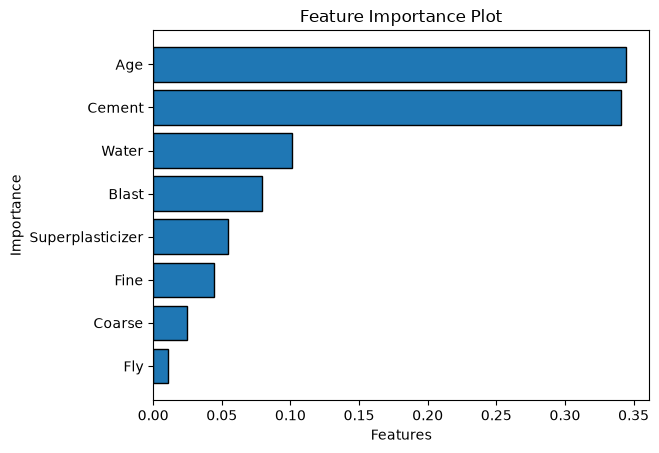

In [47]:
best_model = GradientBoostingRegressor(random_state=26,max_depth=3,n_estimators=100,learning_rate=0.633333)
best_model.fit(X,y)

df_imp = pd.DataFrame({'Features':X.columns,
                       'Importance':best_model.feature_importances_})
df_imp.sort_values('Importance',inplace=True)
plt.barh(df_imp['Features'], df_imp['Importance'],edgecolor='black')
plt.title('Feature Importance Plot')
plt.xlabel('Features')
plt.ylabel('Importance')
plt.show()

# XGB (Extreme Gradient Boosting)

In [48]:
from xgboost import XGBClassifier

In [49]:
df = pd.read_csv(r"C:\Users\PGCP-AI.STUDENTSDC\Desktop\Machine_Learning\Cases\human-resources-analytics\HR_comma_sep.csv")
df.sample(5)

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,Department,salary
3516,0.52,0.44,3,119,2,0,0,0,sales,low
5326,0.59,0.51,3,203,2,1,0,0,IT,medium
6315,0.98,0.81,4,266,6,0,0,0,IT,medium
14931,0.40,0.49,2,143,3,0,1,0,product_mng,medium
12952,0.84,0.86,3,199,3,0,0,0,IT,medium


In [50]:
X , y = df.drop('left',axis=1) , df['left']
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.3,random_state=26,stratify=y)

In [51]:
encoder = OneHotEncoder(sparse_output=False,drop='first')
ct = make_column_transformer((encoder,make_column_selector(dtype_include='object')),
                             ('passthrough',make_column_selector(dtype_include='number')),
                             verbose_feature_names_out=False).set_output(transform='pandas')
X_tr_oh = ct.fit_transform(X_train)
X_ts_oh = ct.transform(X_test)

### Using GradientBoostingClassifier() -> to test speed

In [57]:
learning_rate = np.linspace(0.1,0.9,10)
max_depth = [None,2,3,4]
n_estimators = [25,50,100]
scores = []

for l in tqdm(learning_rate):
    for d in max_depth:
        for n in n_estimators:
            gbm = GradientBoostingClassifier(random_state=26,max_depth=d,n_estimators=n,learning_rate=l)
            gbm.fit(X_tr_oh,y_train)
            y_pred = gbm.predict(X_ts_oh)
            scores.append([l,d,n,accuracy_score(y_test,y_pred)])
df_scores = pd.DataFrame(scores,columns=['Learning Rate','Max Depth','N Estimators','Accuracy'])
df_scores.sort_values('Accuracy',ascending=False,ignore_index=True)

100%|██████████| 10/10 [02:02<00:00, 12.20s/it]


,Learning Rate,Max Depth,N Estimators,Accuracy
0,0.811111,4.0,100,0.985775
1,0.544444,4.0,100,0.984886
2,0.811111,4.0,50,0.984219
3,0.455556,4.0,100,0.983552
4,0.633333,4.0,100,0.982885
...,...,...,...,...
115,0.100000,2.0,50,0.956212
116,0.188889,2.0,25,0.949767
117,0.900000,4.0,50,0.910425
118,0.100000,2.0,25,0.907535


### Using XGBoostClassifier()

In [58]:
learning_rate = np.linspace(0.1,0.9,10)
max_depth = [None,2,3,4]
n_estimators = [25,50,100]
scores = []

for l in tqdm(learning_rate):
    for d in max_depth:
        for n in n_estimators:
            gbm = XGBClassifier(random_state=26,max_depth=d,n_estimators=n,learning_rate=l)
            gbm.fit(X_tr_oh,y_train)
            y_pred = gbm.predict(X_ts_oh)
            scores.append([l,d,n,accuracy_score(y_test,y_pred)])
df_scores = pd.DataFrame(scores,columns=['Learning Rate','Max Depth','N Estimators','Accuracy'])
df_scores.sort_values('Accuracy',ascending=False,ignore_index=True)

100%|██████████| 10/10 [00:18<00:00,  1.89s/it]


,Learning Rate,Max Depth,N Estimators,Accuracy
0,0.544444,NaN,50,0.987997
1,0.544444,NaN,100,0.987997
2,0.455556,NaN,100,0.987775
3,0.900000,NaN,50,0.987553
4,0.633333,NaN,50,0.987331
...,...,...,...,...
115,0.188889,2.0,50,0.968882
116,0.277778,2.0,25,0.965992
117,0.100000,2.0,50,0.957102
118,0.188889,2.0,25,0.956435


# Light GBM

In [60]:
from lightgbm import LGBMClassifier

In [64]:
learning_rate = np.linspace(0.1,0.9,10)
max_depth = [None,2,3,4]
n_estimators = [25,50,100]
scores = []

for l in tqdm(learning_rate):
    for d in max_depth:
        for n in n_estimators:
            lgbm = LGBMClassifier(random_state=26,verbose=-1,max_depth=d,n_estimators=n,learning_rate=l)
            lgbm.fit(X_tr_oh,y_train)
            y_pred = lgbm.predict(X_ts_oh)
            scores.append([l,d,n,accuracy_score(y_test,y_pred)])
df_scores = pd.DataFrame(scores,columns=['Learning Rate','Max Depth','N Estimators','Accuracy'])
df_scores.sort_values('Accuracy',ascending=False,ignore_index=True)

100%|██████████| 10/10 [00:05<00:00,  1.73it/s]


,Learning Rate,Max Depth,N Estimators,Accuracy
0,0.366667,NaN,100,0.989331
1,0.277778,NaN,100,0.989331
2,0.366667,NaN,50,0.988664
3,0.544444,NaN,100,0.988664
4,0.544444,NaN,50,0.988664
...,...,...,...,...
115,0.100000,2.0,25,0.911314
116,0.900000,4.0,100,0.908424
117,0.900000,NaN,100,0.825517
118,0.722222,NaN,100,0.786397


# CatBoost

In [66]:
from catboost import CatBoostClassifier

In [69]:
learning_rate = np.linspace(0.1,0.9,10)
max_depth = [None,2,3,4]
n_estimators = [25,50,100]
scores = []

for l in tqdm(learning_rate):
    for d in max_depth:
        for n in n_estimators:
            cbc = CatBoostClassifier(random_state=26,verbose=False,max_depth=d,n_estimators=n,learning_rate=l)
            cbc.fit(X_tr_oh,y_train)
            y_pred = cbc.predict(X_ts_oh)
            scores.append([l,d,n,accuracy_score(y_test,y_pred)])
df_scores = pd.DataFrame(scores,columns=['Learning Rate','Max Depth','N Estimators','Accuracy'])
df_scores.sort_values('Accuracy',ascending=False,ignore_index=True)

100%|██████████| 10/10 [00:23<00:00,  2.38s/it]


,Learning Rate,Max Depth,N Estimators,Accuracy
0,0.811111,NaN,100,0.981551
1,0.633333,NaN,100,0.981329
2,0.900000,NaN,100,0.980440
3,0.722222,NaN,100,0.979773
4,0.811111,4.0,100,0.979773
...,...,...,...,...
115,0.100000,3.0,25,0.963992
116,0.100000,2.0,50,0.960658
117,0.188889,2.0,25,0.960213
118,0.277778,2.0,25,0.957991


In [77]:
# Without Encoding Categorical Features

categories = ['Department','salary']  # it not perform encoding internally it uses some different approch 
# we might get good performance due to this support

cbc = CatBoostClassifier(random_state=26,verbose=False,max_depth=None,n_estimators=100,learning_rate=0.811111,cat_features=categories) 
cbc.fit(X_train,y_train)
y_pred = cbc.predict(X_test)
accuracy_score(y_test,y_pred)

0.9806623694154256

In [76]:
learning_rate = np.linspace(0.1,0.9,10)
max_depth = [None,2,3,4]
n_estimators = [25,50,100]
scores = []
# X_train and X_test are not an Encoded data
# Using cat_features = assign categorical features 
for l in tqdm(learning_rate):
    for d in max_depth:
        for n in n_estimators:
            cbc = CatBoostClassifier(random_state=26,verbose=False,max_depth=d,n_estimators=n,learning_rate=l,cat_features=categories)
            cbc.fit(X_train,y_train)
            y_pred = cbc.predict(X_test)
            scores.append([l,d,n,accuracy_score(y_test,y_pred)])
df_scores = pd.DataFrame(scores,columns=['Learning Rate','Max Depth','N Estimators','Accuracy'])
df_scores.sort_values('Accuracy',ascending=False,ignore_index=True)

100%|██████████| 10/10 [02:04<00:00, 12.47s/it]


,Learning Rate,Max Depth,N Estimators,Accuracy
0,0.900000,NaN,100,0.980885
1,0.811111,NaN,100,0.980662
2,0.722222,NaN,100,0.979329
3,0.633333,NaN,100,0.978217
4,0.455556,NaN,100,0.977995
...,...,...,...,...
115,0.277778,2.0,25,0.964659
116,0.366667,2.0,25,0.964214
117,0.188889,2.0,25,0.956879
118,0.100000,2.0,50,0.955323


# Exercise

In [78]:
df = pd.read_csv(r"C:\Users\PGCP-AI.STUDENTSDC\Desktop\Machine_Learning\Cases\Vehicle Silhouettes\Vehicle.csv")
df.sample(5)

,Comp,Circ,D.Circ,Rad.Ra,Pr.Axis.Ra,Max.L.Ra,Scat.Ra,Elong,Pr.Axis.Rect,Max.L.Rect,Sc.Var.Maxis,Sc.Var.maxis,Ra.Gyr,Skew.Maxis,Skew.maxis,Kurt.maxis,Kurt.Maxis,Holl.Ra,Class
739,96,44,85,166,66,10,155,43,19,150,167,355,159,67,3,10,192,202,van
481,104,54,91,209,67,11,218,31,24,170,223,697,196,74,4,21,187,196,opel
684,99,38,74,184,66,6,164,39,20,131,193,414,137,71,2,22,200,202,bus
178,93,37,73,174,68,7,151,43,19,131,175,347,135,68,1,22,196,205,bus
693,90,46,75,133,55,11,160,43,20,161,173,369,171,77,0,16,182,192,van


In [113]:
X , y = df.drop('Class',axis=1) , df['Class']
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.3,random_state=26,stratify=y)

In [114]:
learning_rate = np.linspace(0.1,0.9,10)
max_depth = [None,2,3,4]
n_estimators = [25,50,100]
model_comp = {'Model':[],
             'Accuracy':[]}

In [115]:
scores = []

for l in tqdm(learning_rate):
    for d in max_depth:
        for n in n_estimators:
            gbm = GradientBoostingClassifier(random_state=26,max_depth=d,n_estimators=n,learning_rate=l)
            gbm.fit(X_train,y_train)
            y_pred = gbm.predict(X_test)
            scores.append([l,d,n,accuracy_score(y_test,y_pred)])
df_scores = pd.DataFrame(scores,columns=['Learning Rate','Max Depth','N Estimators','Accuracy'])
df_scores.sort_values('Accuracy',ascending=False,ignore_index=True,inplace=True)
model_comp['Model'].append('GradientBoostingClassifier')
model_comp['Accuracy'].append(df_scores['Accuracy'].iloc[0].item())
df_scores

100%|██████████| 10/10 [01:28<00:00,  8.87s/it]


,Learning Rate,Max Depth,N Estimators,Accuracy
0,0.544444,2.0,25,0.791339
1,0.633333,2.0,50,0.775591
2,0.722222,3.0,50,0.771654
3,0.722222,3.0,25,0.771654
4,0.722222,4.0,100,0.771654
...,...,...,...,...
115,0.722222,NaN,50,0.696850
116,0.811111,NaN,100,0.696850
117,0.811111,NaN,50,0.696850
118,0.811111,NaN,25,0.696850


In [116]:
from sklearn.preprocessing import LabelEncoder
encoder = LabelEncoder()
y_tr_en = encoder.fit_transform(y_train.values.reshape(-1,1))
y_ts_en = encoder.transform(y_test.values.reshape(-1,1))

In [117]:
scores = []

for l in tqdm(learning_rate):
    for d in max_depth:
        for n in n_estimators:
            gbm = XGBClassifier(random_state=26,max_depth=d,n_estimators=n,learning_rate=l)
            gbm.fit(X_train,y_tr_en)
            y_pred = gbm.predict(X_test)
            scores.append([l,d,n,accuracy_score(y_ts_en,y_pred)])
df_scores = pd.DataFrame(scores,columns=['Learning Rate','Max Depth','N Estimators','Accuracy'])
df_scores.sort_values('Accuracy',ascending=False,ignore_index=True,inplace=True)
model_comp['Model'].append('XGBClassifier')
model_comp['Accuracy'].append(df_scores['Accuracy'].iloc[0].item())
df_scores

100%|██████████| 10/10 [00:25<00:00,  2.53s/it]


,Learning Rate,Max Depth,N Estimators,Accuracy
0,0.188889,3.0,100,0.791339
1,0.277778,2.0,100,0.791339
2,0.544444,4.0,50,0.791339
3,0.544444,NaN,100,0.791339
4,0.544444,4.0,100,0.791339
...,...,...,...,...
115,0.100000,4.0,25,0.728346
116,0.100000,2.0,50,0.720472
117,0.188889,2.0,25,0.716535
118,0.100000,3.0,25,0.696850


In [118]:
scores = []

for l in tqdm(learning_rate):
    for d in max_depth:
        for n in n_estimators:
            lgbm = LGBMClassifier(random_state=26,verbose=-1,max_depth=d,n_estimators=n,learning_rate=l)
            lgbm.fit(X_train,y_train)
            y_pred = lgbm.predict(X_test)
            scores.append([l,d,n,accuracy_score(y_test,y_pred)])
df_scores = pd.DataFrame(scores,columns=['Learning Rate','Max Depth','N Estimators','Accuracy'])
df_scores.sort_values('Accuracy',ascending=False,ignore_index=True,inplace=True)
model_comp['Model'].append('LGBMClassifier')
model_comp['Accuracy'].append(df_scores['Accuracy'].iloc[0].item())
df_scores

100%|██████████| 10/10 [00:06<00:00,  1.57it/s]


,Learning Rate,Max Depth,N Estimators,Accuracy
0,0.277778,2.0,100,0.807087
1,0.544444,3.0,50,0.803150
2,0.811111,3.0,25,0.803150
3,0.811111,2.0,50,0.799213
4,0.455556,4.0,100,0.795276
...,...,...,...,...
115,0.100000,NaN,25,0.728346
116,0.100000,4.0,50,0.724409
117,0.100000,4.0,25,0.720472
118,0.100000,2.0,25,0.716535


In [ ]:
scores = []

for l in tqdm(learning_rate):
    for d in max_depth:
        for n in n_estimators:
            cbc = CatBoostClassifier(random_state=26,verbose=False,max_depth=d,n_estimators=n,learning_rate=l)
            cbc.fit(X_train,y_train)
            y_pred = cbc.predict(X_test)
            scores.append([l,d,n,accuracy_score(y_test,y_pred)])
df_scores = pd.DataFrame(scores,columns=['Learning Rate','Max Depth','N Estimators','Accuracy'])
df_scores.sort_values('Accuracy',ascending=False,ignore_index=True,inplace=True)
model_comp['Model'].append('CatBoostClassifier')
model_comp['Accuracy'].append(df_scores['Accuracy'].iloc[0].item())
df_scores


In [120]:
models = pd.DataFrame(model_comp)
models.sort_values('Accuracy',ascending=False)

,Model,Accuracy
2,LGBMClassifier,0.807087
0,GradientBoostingClassifier,0.791339
1,XGBClassifier,0.791339
3,CatBoostClassifier,0.783465


# Exercise

In [188]:
df = pd.read_csv(r"C:\Users\PGCP-AI.STUDENTSDC\Desktop\Machine_Learning\Cases\Medical_Cost_Personal\insurance.csv")
df.sample(5)

,age,sex,bmi,children,smoker,region,charges
337,62,male,27.550,1,no,northwest,13937.66650
449,35,male,38.600,1,no,southwest,4762.32900
59,34,female,37.335,2,no,northwest,5989.52365
541,20,female,31.790,2,no,southeast,3056.38810
190,61,male,31.570,0,no,southeast,12557.60530


In [189]:
X , y = df.drop('charges',axis=1) , df['charges']
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.3,random_state=26)

In [190]:
encoder = OneHotEncoder(sparse_output=False,drop='first')
ct = make_column_transformer((encoder,make_column_selector(dtype_include='object')),
                             ('passthrough',make_column_selector(dtype_include='number')),
                             verbose_feature_names_out=False).set_output(transform='pandas')
X_tr_en = ct.fit_transform(X_train)
X_ts_en = ct.transform(X_test)

In [137]:
learning_rate = np.linspace(0.1,0.9,10)
max_depth = [None,2,3,4]
n_estimators = [25,50,100]
model_comp = {'Model':[],
             'R2 Score':[]}

In [138]:
scores = []

for l in tqdm(learning_rate):
    for d in max_depth:
        for n in n_estimators:
            gbm = GradientBoostingRegressor(random_state=26,max_depth=d,n_estimators=n,learning_rate=l)
            gbm.fit(X_tr_en,y_train)
            y_pred = gbm.predict(X_ts_en)
            scores.append([l,d,n,r2_score(y_test,y_pred)])
df_scores = pd.DataFrame(scores,columns=['Learning Rate','Max Depth','N Estimators','R2 Score'])
df_scores.sort_values('R2 Score',ascending=False,ignore_index=True,inplace=True)
model_comp['Model'].append('GradientBoostingRegressor')
model_comp['R2 Score'].append(df_scores['R2 Score'].iloc[0].item())
df_scores

100%|██████████| 10/10 [00:13<00:00,  1.31s/it]


,Learning Rate,Max Depth,N Estimators,R2 Score
0,0.100000,3.0,50,0.870146
1,0.188889,3.0,50,0.869051
2,0.100000,3.0,100,0.868899
3,0.188889,3.0,25,0.868443
4,0.277778,3.0,25,0.867460
...,...,...,...,...
115,0.811111,NaN,25,0.777883
116,0.811111,NaN,50,0.777883
117,0.900000,NaN,100,0.775441
118,0.900000,NaN,25,0.775441


In [140]:
from xgboost import XGBRegressor
scores = []

for l in tqdm(learning_rate):
    for d in max_depth:
        for n in n_estimators:
            gbm = XGBRegressor(random_state=26,max_depth=d,n_estimators=n,learning_rate=l)
            gbm.fit(X_tr_en,y_train)
            y_pred = gbm.predict(X_ts_en)
            scores.append([l,d,n,r2_score(y_test,y_pred)])
df_scores = pd.DataFrame(scores,columns=['Learning Rate','Max Depth','N Estimators','R2 Score'])
df_scores.sort_values('R2 Score',ascending=False,ignore_index=True,inplace=True)
model_comp['Model'].append('XGBRegressor')
model_comp['R2 Score'].append(df_scores['R2 Score'].iloc[0].item())
df_scores

100%|██████████| 10/10 [00:15<00:00,  1.59s/it]


,Learning Rate,Max Depth,N Estimators,R2 Score
0,0.100000,3.0,100,0.873379
1,0.277778,3.0,25,0.873311
2,0.100000,3.0,50,0.872811
3,0.188889,3.0,25,0.871941
4,0.277778,3.0,50,0.871597
...,...,...,...,...
115,0.900000,4.0,100,0.816797
116,0.811111,4.0,100,0.814836
117,0.900000,NaN,25,0.805769
118,0.900000,NaN,50,0.800970


In [141]:
from lightgbm import LGBMRegressor
scores = []

for l in tqdm(learning_rate):
    for d in max_depth:
        for n in n_estimators:
            lgbm = LGBMRegressor(random_state=26,verbose=-1,max_depth=d,n_estimators=n,learning_rate=l)
            lgbm.fit(X_tr_en,y_train)
            y_pred = lgbm.predict(X_ts_en)
            scores.append([l,d,n,r2_score(y_test,y_pred)])
df_scores = pd.DataFrame(scores,columns=['Learning Rate','Max Depth','N Estimators','R2 Score'])
df_scores.sort_values('R2 Score',ascending=False,ignore_index=True,inplace=True)
model_comp['Model'].append('LGBMRegressor')
model_comp['R2 Score'].append(df_scores['R2 Score'].iloc[0].item())
df_scores

100%|██████████| 10/10 [00:02<00:00,  4.02it/s]


,Learning Rate,Max Depth,N Estimators,R2 Score
0,0.277778,3.0,25,0.871497
1,0.100000,3.0,50,0.870092
2,0.188889,3.0,25,0.869795
3,0.100000,2.0,100,0.869708
4,0.188889,2.0,100,0.869656
...,...,...,...,...
115,0.900000,NaN,25,0.823020
116,0.722222,NaN,100,0.819853
117,0.811111,NaN,100,0.817781
118,0.900000,NaN,50,0.812796


In [142]:
from catboost import CatBoostRegressor
scores = []

for l in tqdm(learning_rate):
    for d in max_depth:
        for n in n_estimators:
            cbc = CatBoostRegressor(random_state=26,verbose=False,max_depth=d,n_estimators=n,learning_rate=l)
            cbc.fit(X_tr_en,y_train)
            y_pred = cbc.predict(X_ts_en)
            scores.append([l,d,n,r2_score(y_test,y_pred)])
df_scores = pd.DataFrame(scores,columns=['Learning Rate','Max Depth','N Estimators','R2 Score'])
df_scores.sort_values('R2 Score',ascending=False,ignore_index=True,inplace=True)
model_comp['Model'].append('CatBoostRegressor')
model_comp['R2 Score'].append(df_scores['R2 Score'].iloc[0].item())
df_scores

100%|██████████| 10/10 [00:11<00:00,  1.11s/it]


,Learning Rate,Max Depth,N Estimators,R2 Score
0,0.366667,3.0,50,0.875162
1,0.366667,3.0,25,0.875095
2,0.188889,3.0,50,0.874736
3,0.188889,3.0,100,0.873482
4,0.100000,3.0,100,0.872848
...,...,...,...,...
115,0.633333,NaN,100,0.836068
116,0.811111,NaN,50,0.833312
117,0.811111,NaN,100,0.828422
118,0.900000,NaN,100,0.828038


In [151]:
scores = []

for l in tqdm(learning_rate):
    for d in max_depth:
        for n in n_estimators:
            cbc = CatBoostRegressor(random_state=26,verbose=False,max_depth=d,n_estimators=n,learning_rate=l,cat_features=['sex','smoker','region'])
            cbc.fit(X_train,y_train)
            y_pred = cbc.predict(X_test)
            scores.append([l,d,n,r2_score(y_test,y_pred)])
df_scores = pd.DataFrame(scores,columns=['Learning Rate','Max Depth','N Estimators','R2 Score'])
df_scores.sort_values('R2 Score',ascending=False,ignore_index=True,inplace=True)
model_comp['Model'].append('CatBoostRegressor With cat_feature')
model_comp['R2 Score'].append(df_scores['R2 Score'].iloc[0].item())
df_scores

100%|██████████| 10/10 [01:39<00:00,  9.90s/it]


,Learning Rate,Max Depth,N Estimators,R2 Score
0,0.100000,3.0,100,0.873029
1,0.188889,3.0,50,0.872295
2,0.277778,3.0,50,0.871808
3,0.100000,4.0,100,0.871445
4,0.455556,3.0,25,0.871437
...,...,...,...,...
115,0.811111,NaN,50,0.841540
116,0.900000,NaN,100,0.837391
117,0.722222,NaN,100,0.836774
118,0.811111,NaN,100,0.832396


In [152]:
models = pd.DataFrame(model_comp)
models.sort_values('R2 Score',ascending=False)

,Model,R2 Score
3,CatBoostRegressor,0.875162
1,XGBClassifier,0.873379
4,CatBoostRegressor With cat_feature,0.873029
2,LGBMRegressor,0.871497
0,GradientBoostingRegressor,0.870146


In [194]:
# Using For Loop
models = ['CatBoostRegressor','XGBRegressor','LGBMRegressor','GradientBoostingRegressor']
learning_rate = np.linspace(0.1,0.9,10)
max_depth = [None,2,3,4]
n_estimators = [25,50,100]
scores = []

for model in tqdm(models):
    for l in learning_rate:
        for d in max_depth:
            for n in n_estimators:
                # if model in [LGBMRegressor]:
                #     md = model(random_state=26,verbose=-1,max_depth=d,n_estimators=n,learning_rate=l)
                # elif model in [CatBoostRegressor]:
                #     md = model(random_state=26,verbose=False,max_depth=d,n_estimators=n,learning_rate=l)
                # else:
                md = model(random_state=26,max_depth=d,n_estimators=n,learning_rate=l)
                md.fit(X_tr_en,y_train)
                y_pred = md.predict(X_ts_en)
                scores.append([md,l,d,n,r2_score(y_test,y_pred)])
df_scores = pd.DataFrame(scores,columns=['Model','Learning Rate','Max Depth','N Estimators','R2 Score'])
df_scores.sort_values('R2 Score',ascending=False)

  0%|          | 0/4 [00:00<?, ?it/s]

0:	learn: 10924.5053487	total: 2.13ms	remaining: 51.1ms
1:	learn: 10250.5309821	total: 3.84ms	remaining: 44.2ms
2:	learn: 9553.1923124	total: 5.62ms	remaining: 41.2ms
3:	learn: 8913.6146076	total: 7.55ms	remaining: 39.7ms
4:	learn: 8356.7474956	total: 9.32ms	remaining: 37.3ms
5:	learn: 7875.7919530	total: 11ms	remaining: 34.9ms
6:	learn: 7432.7922621	total: 12.6ms	remaining: 32.5ms
7:	learn: 7042.8823696	total: 14.2ms	remaining: 30.2ms
8:	learn: 6728.0654409	total: 16ms	remaining: 28.5ms
9:	learn: 6398.7171363	total: 17.7ms	remaining: 26.6ms
10:	learn: 6143.5618695	total: 19.3ms	remaining: 24.6ms
11:	learn: 5881.3033404	total: 21ms	remaining: 22.7ms
12:	learn: 5664.4417622	total: 22.6ms	remaining: 20.9ms
13:	learn: 5467.0686670	total: 24.3ms	remaining: 19.1ms
14:	learn: 5316.3224821	total: 24.9ms	remaining: 16.6ms
15:	learn: 5170.9390613	total: 26.6ms	remaining: 15ms
16:	learn: 5042.9882616	total: 28.2ms	remaining: 13.3ms
17:	learn: 4931.5309929	total: 29.9ms	remaining: 11.6ms
18:	lear

 25%|██▌       | 1/4 [00:11<00:35, 11.74s/it]

33:	learn: 3448.5859011	total: 31.6ms	remaining: 14.9ms
34:	learn: 3428.7491085	total: 32.7ms	remaining: 14ms
35:	learn: 3408.2035697	total: 33.7ms	remaining: 13.1ms
36:	learn: 3367.8740697	total: 34.6ms	remaining: 12.1ms
37:	learn: 3354.4540371	total: 35.4ms	remaining: 11.2ms
38:	learn: 3333.3736876	total: 36.3ms	remaining: 10.2ms
39:	learn: 3308.9341943	total: 37.2ms	remaining: 9.3ms
40:	learn: 3294.7925578	total: 38.1ms	remaining: 8.37ms
41:	learn: 3277.5427593	total: 39ms	remaining: 7.43ms
42:	learn: 3273.5747905	total: 39.9ms	remaining: 6.49ms
43:	learn: 3242.4423060	total: 40.8ms	remaining: 5.56ms
44:	learn: 3222.5998353	total: 41.6ms	remaining: 4.63ms
45:	learn: 3202.1194054	total: 42.5ms	remaining: 3.69ms
46:	learn: 3187.5809347	total: 43.4ms	remaining: 2.77ms
47:	learn: 3129.9862724	total: 44.3ms	remaining: 1.84ms
48:	learn: 3119.3318685	total: 45.2ms	remaining: 921us
49:	learn: 3112.5045094	total: 46ms	remaining: 0us
0:	learn: 5887.0214103	total: 1.07ms	remaining: 106ms
1:	le

 50%|█████     | 2/4 [00:27<00:28, 14.25s/it]

Done


 75%|███████▌  | 3/4 [00:30<00:08,  8.86s/it]

Done


100%|██████████| 4/4 [00:44<00:00, 11.01s/it]

Done


In [197]:
df_scores.sort_values('R2 Score',ascending=False,ignore_index=True,inplace=True)

# ----- Stack Ensembling Technique -----

In [274]:
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.ensemble import GradientBoostingClassifier

from sklearn.ensemble import StackingClassifier

In [275]:
df = pd.read_csv(r"C:\Users\PGCP-AI.STUDENTSDC\Desktop\Machine_Learning\Cases\Vehicle Silhouettes\Vehicle.csv")
df.sample(5)

,Comp,Circ,D.Circ,Rad.Ra,Pr.Axis.Ra,Max.L.Ra,Scat.Ra,Elong,Pr.Axis.Rect,Max.L.Rect,Sc.Var.Maxis,Sc.Var.maxis,Ra.Gyr,Skew.Maxis,Skew.maxis,Kurt.maxis,Kurt.Maxis,Holl.Ra,Class
255,112,50,110,186,56,11,214,31,24,159,232,676,203,71,18,27,191,202,saab
31,88,42,77,151,58,8,140,47,18,142,165,293,158,64,10,11,198,205,saab
508,95,46,92,159,63,11,160,42,20,157,176,372,171,70,7,21,189,200,van
19,101,56,100,215,69,10,208,32,24,169,227,651,223,74,6,5,186,193,opel
6,97,43,73,173,65,6,153,42,19,143,176,361,172,66,13,1,200,204,bus


In [276]:
X , y = df.drop('Class',axis=1) , df['Class']
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.3,random_state=26,stratify=y)

In [277]:
nb = GaussianNB()
lr = LogisticRegression()
dtc = DecisionTreeClassifier()
lda = LinearDiscriminantAnalysis()
gbm = GradientBoostingClassifier()

stack = StackingClassifier(estimators=[('Tree',dtc),('LR',lr),('LDA',lda),('NB',nb)],final_estimator=gbm)
stack.fit(X_train,y_train)

,"estimators estimators: list of (str, estimator)Base estimators which will be stacked together. Each element of thelist is defined as a tuple of string (i.e. name) and an estimatorinstance. An estimator can be set to 'drop' using `set_params`.The type of estimator is generally expected to be a classifier.However, one can pass a regressor for some use case (e.g. ordinalregression).","[('Tree', ...), ('LR', ...), ...]"
,"final_estimator final_estimator: estimator, default=NoneA classifier which will be used to combine the base estimators.The default classifier is a:class:`~sklearn.linear_model.LogisticRegression`.",GradientBoostingClassifier()
,"cv cv: int, cross-validation generator, iterable, or ""prefit"", default=NoneDetermines the cross-validation splitting strategy used in`cross_val_predict` to train `final_estimator`. Possible inputs forcv are:* None, to use the default 5-fold cross validation,* integer, to specify the number of folds in a (Stratified) KFold,* An object to be used as a cross-validation generator,* An iterable yielding train, test splits,* `""prefit""`, to assume the `estimators` are prefit. In this case, the estimators will not be refitted.For integer/None inputs, if the estimator is a classifier and y iseither binary or multiclass,:class:`~sklearn.model_selection.StratifiedKFold` is used.In all other cases, :class:`~sklearn.model_selection.KFold` is used.These splitters are instantiated with `shuffle=False` so the splitswill be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here.If ""prefit"" is passed, it is assumed that all `estimators` havebeen fitted already. The `final_estimator_` is trained on the `estimators`predictions on the full training set and are **not** cross validatedpredictions. Please note that if the models have been trained on the samedata to train the stacking model, there is a very high risk of overfitting... versionadded:: 1.1 The 'prefit' option was added in 1.1.. note:: A larger number of split will provide no benefits if the number of training samples is large enough. Indeed, the training time will increase. ``cv`` is not used for model evaluation but for prediction.",None
,"stack_method stack_method: {'auto', 'predict_proba', 'decision_function', 'predict'}, default='auto'Methods called for each base estimator. It can be:* if 'auto', it will try to invoke, for each estimator, `'predict_proba'`, `'decision_function'` or `'predict'` in that order.* otherwise, one of `'predict_proba'`, `'decision_function'` or `'predict'`. If the method is not implemented by the estimator, it will raise an error.",'auto'
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for `fit` of all `estimators`.`None` means 1 unless in a `joblib.parallel_backend` context. -1 meansusing all processors. See :term:`Glossary <n_jobs>` for more details.",None
,"passthrough passthrough: bool, default=FalseWhen False, only the predictions of estimators will be used astraining data for `final_estimator`. When True, the`final_estimator` is trained on the predictions as well as theoriginal training data.",False
,"verbose verbose: int, default=0Verbosity level.",0
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,) or list of ndarray if `y` is of type `""multilabel-indicator""`.Class labels.","ndarray[object](4,)","['bus','opel','saab','van']"
"estimators_ estimators_: list of estimatorsThe elements of the `estimators` parameter, having been fitted on thetraining data. If an estimator has been set to `'drop'`, itwill not appear in `estimators_`. When `cv=""prefit""`, `estimators_`is set to `estimators` and is not fitted again.",list,"[DecisionTreeClassifier(), LogisticRegression(), LinearDiscriminantAnalysis(), GaussianNB()]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimators expose such an attribute wh

In [278]:
y_pred = stack.predict(X_test)
accuracy_score(y_test,y_pred)

0.7874015748031497

In [235]:
# Using passthrough Option

stack = StackingClassifier(estimators=[('Tree',dtc),('LR',lr),('LDA',lda),('NB',nb)],final_estimator=gbm,passthrough=True)
stack.fit(X_train,y_train)

,"estimators estimators: list of (str, estimator)Base estimators which will be stacked together. Each element of thelist is defined as a tuple of string (i.e. name) and an estimatorinstance. An estimator can be set to 'drop' using `set_params`.The type of estimator is generally expected to be a classifier.However, one can pass a regressor for some use case (e.g. ordinalregression).","[('Tree', ...), ('LR', ...), ...]"
,"final_estimator final_estimator: estimator, default=NoneA classifier which will be used to combine the base estimators.The default classifier is a:class:`~sklearn.linear_model.LogisticRegression`.",GradientBoostingClassifier()
,"passthrough passthrough: bool, default=FalseWhen False, only the predictions of estimators will be used astraining data for `final_estimator`. When True, the`final_estimator` is trained on the predictions as well as theoriginal training data.",True
,"cv cv: int, cross-validation generator, iterable, or ""prefit"", default=NoneDetermines the cross-validation splitting strategy used in`cross_val_predict` to train `final_estimator`. Possible inputs forcv are:* None, to use the default 5-fold cross validation,* integer, to specify the number of folds in a (Stratified) KFold,* An object to be used as a cross-validation generator,* An iterable yielding train, test splits,* `""prefit""`, to assume the `estimators` are prefit. In this case, the estimators will not be refitted.For integer/None inputs, if the estimator is a classifier and y iseither binary or multiclass,:class:`~sklearn.model_selection.StratifiedKFold` is used.In all other cases, :class:`~sklearn.model_selection.KFold` is used.These splitters are instantiated with `shuffle=False` so the splitswill be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here.If ""prefit"" is passed, it is assumed that all `estimators` havebeen fitted already. The `final_estimator_` is trained on the `estimators`predictions on the full training set and are **not** cross validatedpredictions. Please note that if the models have been trained on the samedata to train the stacking model, there is a very high risk of overfitting... versionadded:: 1.1 The 'prefit' option was added in 1.1.. note:: A larger number of split will provide no benefits if the number of training samples is large enough. Indeed, the training time will increase. ``cv`` is not used for model evaluation but for prediction.",None
,"stack_method stack_method: {'auto', 'predict_proba', 'decision_function', 'predict'}, default='auto'Methods called for each base estimator. It can be:* if 'auto', it will try to invoke, for each estimator, `'predict_proba'`, `'decision_function'` or `'predict'` in that order.* otherwise, one of `'predict_proba'`, `'decision_function'` or `'predict'`. If the method is not implemented by the estimator, it will raise an error.",'auto'
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for `fit` of all `estimators`.`None` means 1 unless in a `joblib.parallel_backend` context. -1 meansusing all processors. See :term:`Glossary <n_jobs>` for more details.",None
,"verbose verbose: int, default=0Verbosity level.",0
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,) or list of ndarray if `y` is of type `""multilabel-indicator""`.Class labels.","ndarray[object](4,)","['bus','opel','saab','van']"
"estimators_ estimators_: list of estimatorsThe elements of the `estimators` parameter, having been fitted on thetraining data. If an estimator has been set to `'drop'`, itwill not appear in `estimators_`. When `cv=""prefit""`, `estimators_`is set to `estimators` and is not fitted again.",list,"[DecisionTreeClassifier(), LogisticRegression(), LinearDiscriminantAnalysis(), GaussianNB()]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimators expose such an attribute whe

In [236]:
y_pred = stack.predict(X_test)
accuracy_score(y_test,y_pred)

0.8149606299212598

In [237]:
# Using XGBRegressor
gbm = XGBClassifier(random_state=26)

encoder = LabelEncoder()
y_en = encoder.fit_transform(y)
X_train,X_test,y_train,y_test = train_test_split(X,y_en,test_size=0.3,random_state=26,stratify=y)


stack = StackingClassifier(estimators=[('Tree',dtc),('LR',lr),('LDA',lda),('NB',nb)],final_estimator=gbm)
stack.fit(X_train,y_train)

,"estimators estimators: list of (str, estimator)Base estimators which will be stacked together. Each element of thelist is defined as a tuple of string (i.e. name) and an estimatorinstance. An estimator can be set to 'drop' using `set_params`.The type of estimator is generally expected to be a classifier.However, one can pass a regressor for some use case (e.g. ordinalregression).","[('Tree', ...), ('LR', ...), ...]"
,"final_estimator final_estimator: estimator, default=NoneA classifier which will be used to combine the base estimators.The default classifier is a:class:`~sklearn.linear_model.LogisticRegression`.","XGBClassifier...ree=None, ...)"
,"cv cv: int, cross-validation generator, iterable, or ""prefit"", default=NoneDetermines the cross-validation splitting strategy used in`cross_val_predict` to train `final_estimator`. Possible inputs forcv are:* None, to use the default 5-fold cross validation,* integer, to specify the number of folds in a (Stratified) KFold,* An object to be used as a cross-validation generator,* An iterable yielding train, test splits,* `""prefit""`, to assume the `estimators` are prefit. In this case, the estimators will not be refitted.For integer/None inputs, if the estimator is a classifier and y iseither binary or multiclass,:class:`~sklearn.model_selection.StratifiedKFold` is used.In all other cases, :class:`~sklearn.model_selection.KFold` is used.These splitters are instantiated with `shuffle=False` so the splitswill be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here.If ""prefit"" is passed, it is assumed that all `estimators` havebeen fitted already. The `final_estimator_` is trained on the `estimators`predictions on the full training set and are **not** cross validatedpredictions. Please note that if the models have been trained on the samedata to train the stacking model, there is a very high risk of overfitting... versionadded:: 1.1 The 'prefit' option was added in 1.1.. note:: A larger number of split will provide no benefits if the number of training samples is large enough. Indeed, the training time will increase. ``cv`` is not used for model evaluation but for prediction.",None
,"stack_method stack_method: {'auto', 'predict_proba', 'decision_function', 'predict'}, default='auto'Methods called for each base estimator. It can be:* if 'auto', it will try to invoke, for each estimator, `'predict_proba'`, `'decision_function'` or `'predict'` in that order.* otherwise, one of `'predict_proba'`, `'decision_function'` or `'predict'`. If the method is not implemented by the estimator, it will raise an error.",'auto'
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for `fit` of all `estimators`.`None` means 1 unless in a `joblib.parallel_backend` context. -1 meansusing all processors. See :term:`Glossary <n_jobs>` for more details.",None
,"passthrough passthrough: bool, default=FalseWhen False, only the predictions of estimators will be used astraining data for `final_estimator`. When True, the`final_estimator` is trained on the predictions as well as theoriginal training data.",False
,"verbose verbose: int, default=0Verbosity level.",0
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,) or list of ndarray if `y` is of type `""multilabel-indicator""`.Class labels.","ndarray[int64](4,)","[0,1,2,3]"
"estimators_ estimators_: list of estimatorsThe elements of the `estimators` parameter, having been fitted on thetraining data. If an estimator has been set to `'drop'`, itwill not appear in `estimators_`. When `cv=""prefit""`, `estimators_`is set to `estimators` and is not fitted again.",list,"[DecisionTreeClassifier(), LogisticRegression(), LinearDiscriminantAnalysis(), GaussianNB()]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimators expose such an attribute when fit... versi

In [238]:
y_pred = stack.predict(X_test)
accuracy_score(y_test,y_pred)

0.7755905511811023

In [239]:
stack = StackingClassifier(estimators=[('Tree',dtc),('LR',lr),('LDA',lda),('NB',nb)],final_estimator=gbm,passthrough=True)
stack.fit(X_train,y_train)

,"estimators estimators: list of (str, estimator)Base estimators which will be stacked together. Each element of thelist is defined as a tuple of string (i.e. name) and an estimatorinstance. An estimator can be set to 'drop' using `set_params`.The type of estimator is generally expected to be a classifier.However, one can pass a regressor for some use case (e.g. ordinalregression).","[('Tree', ...), ('LR', ...), ...]"
,"final_estimator final_estimator: estimator, default=NoneA classifier which will be used to combine the base estimators.The default classifier is a:class:`~sklearn.linear_model.LogisticRegression`.","XGBClassifier...ree=None, ...)"
,"passthrough passthrough: bool, default=FalseWhen False, only the predictions of estimators will be used astraining data for `final_estimator`. When True, the`final_estimator` is trained on the predictions as well as theoriginal training data.",True
,"cv cv: int, cross-validation generator, iterable, or ""prefit"", default=NoneDetermines the cross-validation splitting strategy used in`cross_val_predict` to train `final_estimator`. Possible inputs forcv are:* None, to use the default 5-fold cross validation,* integer, to specify the number of folds in a (Stratified) KFold,* An object to be used as a cross-validation generator,* An iterable yielding train, test splits,* `""prefit""`, to assume the `estimators` are prefit. In this case, the estimators will not be refitted.For integer/None inputs, if the estimator is a classifier and y iseither binary or multiclass,:class:`~sklearn.model_selection.StratifiedKFold` is used.In all other cases, :class:`~sklearn.model_selection.KFold` is used.These splitters are instantiated with `shuffle=False` so the splitswill be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here.If ""prefit"" is passed, it is assumed that all `estimators` havebeen fitted already. The `final_estimator_` is trained on the `estimators`predictions on the full training set and are **not** cross validatedpredictions. Please note that if the models have been trained on the samedata to train the stacking model, there is a very high risk of overfitting... versionadded:: 1.1 The 'prefit' option was added in 1.1.. note:: A larger number of split will provide no benefits if the number of training samples is large enough. Indeed, the training time will increase. ``cv`` is not used for model evaluation but for prediction.",None
,"stack_method stack_method: {'auto', 'predict_proba', 'decision_function', 'predict'}, default='auto'Methods called for each base estimator. It can be:* if 'auto', it will try to invoke, for each estimator, `'predict_proba'`, `'decision_function'` or `'predict'` in that order.* otherwise, one of `'predict_proba'`, `'decision_function'` or `'predict'`. If the method is not implemented by the estimator, it will raise an error.",'auto'
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for `fit` of all `estimators`.`None` means 1 unless in a `joblib.parallel_backend` context. -1 meansusing all processors. See :term:`Glossary <n_jobs>` for more details.",None
,"verbose verbose: int, default=0Verbosity level.",0
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,) or list of ndarray if `y` is of type `""multilabel-indicator""`.Class labels.","ndarray[int64](4,)","[0,1,2,3]"
"estimators_ estimators_: list of estimatorsThe elements of the `estimators` parameter, having been fitted on thetraining data. If an estimator has been set to `'drop'`, itwill not appear in `estimators_`. When `cv=""prefit""`, `estimators_`is set to `estimators` and is not fitted again.",list,"[DecisionTreeClassifier(), LogisticRegression(), LinearDiscriminantAnalysis(), GaussianNB()]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimators expose such an attribute when fit... versio

In [240]:
y_pred = stack.predict(X_test)
accuracy_score(y_test,y_pred)

0.7716535433070866

# Exercise

In [282]:
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import StackingRegressor, GradientBoostingRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso 
from sklearn.tree import DecisionTreeRegressor

In [283]:
df = pd.read_csv(r"C:\Users\PGCP-AI.STUDENTSDC\Desktop\Machine_Learning\Cases\Medical_Cost_Personal\insurance.csv")
df.sample(5)

,age,sex,bmi,children,smoker,region,charges
109,63,male,35.09,0,yes,southeast,47055.5321
53,36,male,34.43,0,yes,southeast,37742.5757
993,38,male,28.27,1,no,southeast,5484.4673
650,49,female,42.68,2,no,southeast,9800.8882
22,18,male,34.10,0,no,southeast,1137.0110


In [284]:
X , y = df.drop('charges',axis=1) , df['charges']
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.3,random_state=26)

In [285]:
scaler = StandardScaler()
encoder = OneHotEncoder(sparse_output=False,drop='first')
ct = make_column_transformer((encoder,make_column_selector(dtype_include='object')),
                             ('passthrough',make_column_selector(dtype_include='number')),
                             verbose_feature_names_out=False).set_output(transform='pandas')

In [286]:
lr = LinearRegression()
knn_pipe = Pipeline([('SCL',scaler),('KNN',KNeighborsRegressor())])
ridge = Ridge()
lasso = Lasso()
dtr = DecisionTreeRegressor()
gbm = GradientBoostingRegressor()

stack = StackingRegressor(estimators=[('Tree',dtr),('LR',lr),('RIDGE',ridge),('LASSO',lasso),('KNN',knn_pipe)],
                          final_estimator=gbm,passthrough=True)

pipe = Pipeline([('CT',ct),('STACK',stack)])
pipe.fit(X_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('CT', ...), ('STACK', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['age','sex','bmi','children','smoker','region']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('onehotencoder', ...), ('passthrough', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if

In [287]:
y_pred = pipe.predict(X_test)
r2_score(y_test,y_pred)

0.8640629595685015

In [288]:
stack = StackingRegressor(estimators=[('Tree',dtr),('LR',lr),('RIDGE',ridge),('LASSO',lasso),('KNN',knn_pipe)],
                          final_estimator=gbm)
pipe = Pipeline([('CT',ct),('STACK',stack)])
pipe.fit(X_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('CT', ...), ('STACK', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['age','sex','bmi','children','smoker','region']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('onehotencoder', ...), ('passthrough', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if

In [289]:
y_pred = pipe.predict(X_test)
r2_score(y_test,y_pred)

0.8510540326544049